# 03 · Segments: should each customer get a different e-mail?

Notebook 02 found that **on average** the men's e-mail beats the women's e-mail. But an average can hide
groups that behave differently. For example, customers who only buy women's clothing might respond better to the
women's e-mail. If so, sending each segment its best e-mail (**targeting**) could beat any single campaign.

This notebook answers three questions:
1. **Does the e-mails' effect differ between customer segments?** (sections 2–3)
2. **Is that difference real, or just noise from slicing the data?** (section 4)
3. **Would a targeting rule actually earn more than sending the men's e-mail to everyone?** (section 5)
4. **So which campaign should each key segment get?** A per-segment recommendation for past purchases, new vs
   existing customers, and purchase channel. (section 6)

### Why segment analysis needs extra care
- **Many slices produce false alarms.** This notebook looks at 19 segments × 3 comparisons × 3 metrics = 171
  estimates. At a 5% error rate, about 8 of those could look "significant" by pure chance.
- **Smaller groups give noisier estimates.** Notebook 02 showed that with ~1,000 customers per group, only spend
  effects above ~\$1.45 per customer can be detected. Visit rate is far more informative at segment level.
- **The winner's curse.** If we pick the best-looking e-mail per segment and then measure how well that choice does
  *on the same data*, we partly reward luck, and the gain looks bigger than it really is.

### How we guard against this
- **Segments fixed in advance.** We use only pre-campaign customer attributes, merged so each segment has roughly
  1,000+ customers per group:

| Segment variable | Levels |
|---|---|
| Past purchases | men's only · women's only · both |
| Spend in past year | under \$100 · \$100–350 · \$350–750 · \$750+ |
| Months since last purchase | 1–3 · 4–6 · 7–9 · 10–12 |
| Purchase channel | phone · web · multichannel |
| Area | urban · suburban · rural |
| Customer type | existing · new (past 12 months) |

- **One hypothesis named up front:** *customers respond best to the e-mail that matches what they have bought
  before.* It is the obvious business idea, so we test it directly.
- **Formal tests of "does the effect differ?"** (interaction tests with a Holm correction), instead of eyeballing
  which segments happen to show p < 0.05.
- **Honest evaluation of targeting rules.** Rules are learned on one half of the customers and scored on the other.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

from src.style import ARM_LABELS, ARM_COLORS, set_style
from src.data import load_clean, add_segments, SEGMENTS
from src.stats import two_proportion_test, mean_difference_test, holm
from src.targeting import (cell_means, policy_value, uniform_policy, best_arm_policy,
                           bootstrap_policy_difference, crossfit_gain)

ALPHA = 0.05
SEED = 42
N_BOOT = 2_000   # bootstrap resamples per segment (fewer than notebook 02's 10,000 to keep run time reasonable)
N_SPLITS = 200   # random half/half splits for the honest targeting evaluation
rng = np.random.default_rng(SEED)

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.html.use_mathjax", False)  # show "$" in tables literally, not as math
FIG_DIR = ROOT / "figures"

df = add_segments(load_clean())

# Treatment codes -> readable labels and the project's fixed colours
T_LABEL = {"control": "Control", "mens": "Men's e-mail", "womens": "Women's e-mail"}
T_COLOR = {"control": ARM_COLORS["No E-Mail"], "mens": ARM_COLORS["Mens E-Mail"], "womens": ARM_COLORS["Womens E-Mail"]}
COMPARISONS = [("mens", "control"), ("womens", "control"), ("mens", "womens")]
COMP_LABEL = {c: f"{T_LABEL[c[0]]} vs {T_LABEL[c[1]].lower()}" for c in COMPARISONS}
METRIC_NAMES = {"visit": "Visit rate", "conversion": "Conversion rate", "spend": "Spend per customer"}
print(f"{len(df):,} customers, segment variables: {list(SEGMENTS)}")

64,000 customers, segment variables: ['purchase_history', 'history_tier', 'recency_band', 'channel', 'zip_code', 'customer_type']


## 1. Segment sizes

First, check the size of every segment in every group. Thanks to randomization, each segment is split roughly
equally across the three groups. The smallest segment ("\$750+ spent last year") still has over 1,000 customers per
group, the floor we set when merging the original 7 spending buckets into 4.

In [2]:
sizes = pd.concat(
    {SEGMENTS[s]: df.groupby([s, "treatment"], observed=True).size().unstack() for s in SEGMENTS},
    names=["segment variable", "level"])
sizes.columns = [T_LABEL[c] for c in sizes.columns]
sizes

Control  Men's e-mail  \
segment variable           level                                         
Past purchases             Men's only               9638          9558   
                           Women's only             9519          9568   
                           Both                     2149          2181   
Spend in past year         under $100               7612          7724   
                           $100–350                 8880          8781   
                           $350–750                 3776          3694   
                           $750+                    1038          1108   
Months since last purchase 1–3 months               7438          7469   
                           4–6 months               4766          4673   
                           7–9 months               4699          4688   
                           10–12 months             4403          4477   
Purchase channel           Phone                    9327          9240   
                           Web                      9373          9490   
                           Multichannel             2606          2577   
Area                       Urban                    8542          8563   
                           Suburban                 9625          9501   
                           Rural                    3139          3243   
Customer type              Existing                10611         10621   
                           New (past 12 months)    10695         10686   

                                                 Women's e-mail  
segment variable           level                                 
Past purchases             Men's only                      9622  
                           Women's only                    9647  
                           Both                            2118  
Spend in past year         under $100                      7634  
                           $100–350                        8882  
                           $350–750                        3850  
                           $750+                           1021  
Months since last purchase 1–3 months                      7486  
                           4–6 months                      4753  
                           7–9 months                      4627  
                           10–12 months                    4521  
Purchase channel           Phone                           9454  
                           Web                             9354  
                           Multichannel                    2579  
Area                       Urban                           8556  
                           Suburban                        9650  
                           Rural                           3181  
Customer type              Existing                       10624  
                           New (past 12 months)           10763

## 2. The headline segment: past purchases

This is the segment named in our hypothesis. Each customer bought men's merchandise, women's merchandise, or both
in the past year (every customer in the data belongs to one of the three). The chart shows each group's outcomes
within each kind of buyer. The error bars are 95% intervals: Wilson intervals for rates (accurate for small
percentages), and bootstrap intervals for spend (no distribution assumption, as in notebook 02).

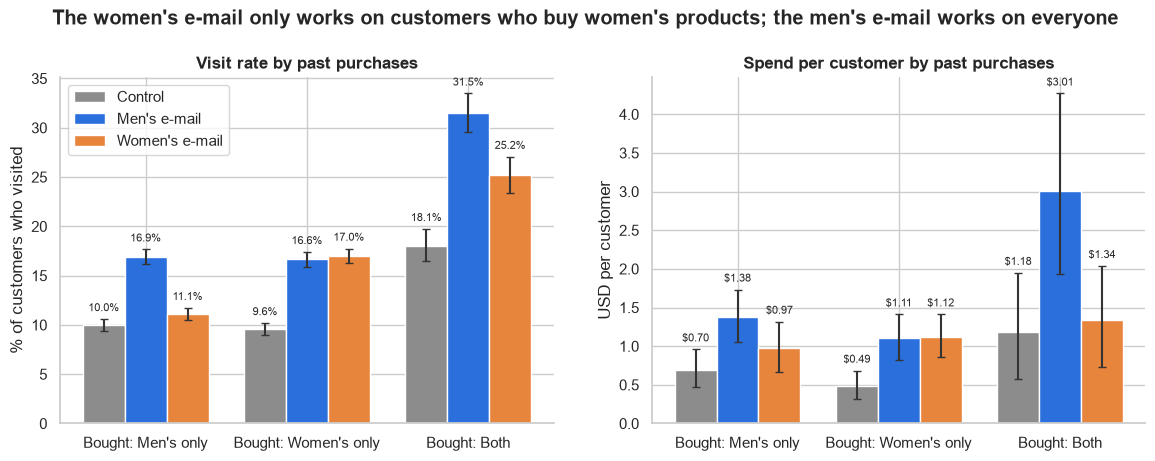

In [3]:
def level_stats(sub, metric):
    # Mean and 95% CI for one cell
    y = sub[metric].to_numpy(float)
    if metric == "spend":
        boots = np.array([y[rng.integers(0, len(y), len(y))].mean() for _ in range(N_BOOT)])
        return y.mean(), *np.percentile(boots, [2.5, 97.5])
    lo, hi = proportion_confint(y.sum(), len(y), alpha=ALPHA, method="wilson")
    return y.mean(), lo, hi

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
levels = list(df.purchase_history.cat.categories)
width = 0.26
for ax, metric in zip(axes, ["visit", "spend"]):
    scale = 1 if metric == "spend" else 100
    for j, t in enumerate(["control", "mens", "womens"]):
        stats_ = [level_stats(df[(df.purchase_history == lv) & (df.treatment == t)], metric) for lv in levels]
        m, lo, hi = (np.array(v) * scale for v in zip(*stats_))
        x = np.arange(len(levels)) + (j - 1) * width
        ax.bar(x, m, width, color=T_COLOR[t], label=T_LABEL[t], yerr=[m - lo, hi - m], capsize=3, ecolor="#333333")
        for xi, mi, hii in zip(x, m, hi):  # value label just above the error bar
            ax.annotate(f"${mi:.2f}" if metric == "spend" else f"{mi:.1f}%", (xi, hii), xytext=(0, 4),
                        textcoords="offset points", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(np.arange(len(levels)), [f"Bought: {lv}" for lv in levels])
    ax.set_ylabel("USD per customer" if metric == "spend" else "% of customers who visited")
    ax.set_title(METRIC_NAMES[metric] + " by past purchases")
axes[0].legend(loc="upper left")
fig.suptitle("The women's e-mail only works on customers who buy women's products; the men's e-mail works on everyone",
             fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "03_purchase_history.png")
plt.show()

## 3. Effects in every segment

Next, the effect of each e-mail versus control (and of men's versus women's) is estimated separately inside every
segment, with the same methods as notebook 02:
- **Rates:** two-proportion z-test and Newcombe interval.
- **Spend:** bootstrap interval and Welch's t-test.

These are **descriptive**. A segment where an effect is "significant" next to one where it isn't does **not** prove
the effects differ, because the smaller segment may simply have too little data. Section 4 tests differences
properly.

In [4]:
rows = []
for seg in SEGMENTS:
    for level in df[seg].cat.categories:
        sub = df[df[seg] == level]
        for a, b in COMPARISONS:
            ya, yb = sub[sub.treatment == a], sub[sub.treatment == b]
            for metric in ["visit", "conversion", "spend"]:
                if metric == "spend":
                    r = mean_difference_test(ya.spend, yb.spend, rng, n_boot=N_BOOT, alpha=ALPHA)
                    r.pop("boot_diffs")
                else:
                    r = two_proportion_test(ya[metric], yb[metric], alpha=ALPHA)
                rows.append({"segment": seg, "level": level, "comparison": (a, b), "metric": metric, **r})
seg_res = pd.DataFrame(rows)

def effect_table(metric):
    sub = seg_res[seg_res.metric == metric]
    scale, unit = (1, "$") if metric == "spend" else (100, "pp")
    fmt = lambda d, lo, hi: (f"{d * scale:+.2f} [{lo * scale:+.2f}, {hi * scale:+.2f}]")
    t = sub.assign(segment=sub.segment.map(SEGMENTS), comparison=sub.comparison.map(COMP_LABEL),
                   cell=[fmt(d, lo, hi) for d, lo, hi in zip(sub["diff"], sub.diff_ci_low, sub.diff_ci_high)])
    out = t.pivot_table(index=["segment", "level"], columns="comparison", values="cell", aggfunc="first", sort=False)
    out.columns.name = f"{METRIC_NAMES[metric]}: difference in {unit} [95% CI]"
    return out[[COMP_LABEL[c] for c in COMPARISONS]]

effect_table("visit")

Visit rate: difference in pp [95% CI]            Men's e-mail vs control  \
segment                    level                                           
Past purchases             Men's only               +6.92 [+5.96, +7.88]   
                           Women's only             +7.06 [+6.11, +8.01]   
                           Both                  +13.44 [+10.89, +15.97]   
Spend in past year         under $100               +6.86 [+5.84, +7.88]   
                           $100–350                 +7.66 [+6.63, +8.69]   
                           $350–750                +9.36 [+7.63, +11.09]   
                           $750+                   +7.66 [+4.30, +10.99]   
Months since last purchase 1–3 months               +8.50 [+7.27, +9.72]   
                           4–6 months               +7.55 [+6.14, +8.96]   
                           7–9 months               +7.04 [+5.74, +8.33]   
                           10–12 months             +7.04 [+5.73, +8.36]   
Purchase channel           Phone                    +7.56 [+6.62, +8.51]   
                           Web                      +7.56 [+6.52, +8.59]   
                           Multichannel            +8.29 [+6.26, +10.33]   
Area                       Urban                    +7.96 [+6.94, +8.99]   
                           Suburban                 +7.43 [+6.47, +8.40]   
                           Rural                    +7.34 [+5.42, +9.25]   
Customer type              Existing                 +7.78 [+6.77, +8.79]   
                           New (past 12 months)     +7.53 [+6.68, +8.39]   

Visit rate: difference in pp [95% CI]           Women's e-mail vs control  \
segment                    level                                            
Past purchases             Men's only                +1.11 [+0.24, +1.98]   
                           Women's only              +7.40 [+6.44, +8.35]   
                           Both                      +7.11 [+4.64, +9.57]   
Spend in past year         under $100                +4.68 [+3.70, +5.66]   
                           $100–350                  +3.99 [+3.02, +4.97]   
                           $350–750                  +5.17 [+3.54, +6.81]   
                           $750+                     +5.46 [+2.09, +8.81]   
Months since last purchase 1–3 months                +4.40 [+3.23, +5.57]   
                           4–6 months                +4.05 [+2.72, +5.38]   
                           7–9 months                +5.38 [+4.12, +6.64]   
                           10–12 months              +4.35 [+3.11, +5.60]   
Purchase channel           Phone                     +4.46 [+3.57, +5.35]   
                           Web                       +4.57 [+3.57, +5.56]   
                           Multichannel              +4.71 [+2.76, +6.66]   
Area                       Urban                     +4.69 [+3.72, +5.67]   
                           Suburban                  +4.89 [+3.96, +5.81]   
                           Rural                     +2.91 [+1.07, +4.75]   
Customer type              Existing                  +4.01 [+3.04, +4.98]   
                           New (past 12 months)      +5.04 [+4.23, +5.86]   

Visit rate: difference in pp [95% CI]           Men's e-mail vs women's e-mail  
segment                    level                                                
Past purchases             Men's only                     +5.81 [+4.83, +6.79]  
                           Women's only                   -0.34 [-1.40, +0.72]  
                           Both                           +6.33 [+3.64, +9.01]  
Spend in past year         under $100                     +2.18 [+1.07, +3.28]  
                           $100–350                       +3.67 [+2.57, +4.76]  
                           $350–750                       +4.19 [+2.37, +6.01]  
                           $750+                          +2.20 [-1.35, +5.74]  
Months since last purchase 1–3 months                   

In [5]:
effect_table("spend")

Spend per customer: difference in $ [95% CI]    Men's e-mail vs control  \
segment                    level                                          
Past purchases             Men's only              +0.68 [+0.27, +1.15]   
                           Women's only            +0.62 [+0.28, +0.96]   
                           Both                    +1.82 [+0.47, +3.11]   
Spend in past year         under $100              +0.54 [+0.14, +0.98]   
                           $100–350                +0.63 [+0.21, +1.03]   
                           $350–750                +1.37 [+0.61, +2.13]   
                           $750+                   +1.48 [-0.23, +3.30]   
Months since last purchase 1–3 months              +1.05 [+0.50, +1.67]   
                           4–6 months              +0.49 [+0.00, +0.97]   
                           7–9 months              +0.61 [+0.07, +1.17]   
                           10–12 months            +0.77 [+0.24, +1.39]   
Purchase channel           Phone                   +0.56 [+0.15, +0.97]   
                           Web                     +0.85 [+0.43, +1.34]   
                           Multichannel            +1.21 [+0.48, +2.06]   
Area                       Urban                   +0.74 [+0.32, +1.17]   
                           Suburban                +0.80 [+0.37, +1.25]   
                           Rural                   +0.76 [+0.07, +1.46]   
Customer type              Existing                +0.58 [+0.14, +1.04]   
                           New (past 12 months)    +0.96 [+0.60, +1.33]   

Spend per customer: difference in $ [95% CI]    Women's e-mail vs control  \
segment                    level                                            
Past purchases             Men's only                +0.28 [-0.10, +0.67]   
                           Women's only              +0.63 [+0.30, +0.98]   
                           Both                      +0.16 [-0.86, +1.10]   
Spend in past year         under $100                +0.63 [+0.20, +1.05]   
                           $100–350                  +0.10 [-0.26, +0.43]   
                           $350–750                  +0.50 [-0.10, +1.11]   
                           $750+                     +1.46 [-0.32, +3.40]   
Months since last purchase 1–3 months                +0.36 [-0.09, +0.86]   
                           4–6 months                +0.67 [+0.11, +1.21]   
                           7–9 months                +0.30 [-0.23, +0.85]   
                           10–12 months              +0.41 [+0.00, +0.84]   
Purchase channel           Phone                     +0.23 [-0.14, +0.56]   
                           Web                       +0.42 [+0.03, +0.81]   
                           Multichannel              +1.16 [+0.27, +2.07]   
Area                       Urban                     +0.67 [+0.25, +1.10]   
                           Suburban                  +0.18 [-0.18, +0.56]   
                           Rural                     +0.51 [-0.09, +1.12]   
Customer type              Existing                  +0.11 [-0.26, +0.50]   
                           New (past 12 months)      +0.73 [+0.41, +1.06]   

Spend per customer: difference in $ [95% CI]    Men's e-mail vs women's e-mail  
segment                    level                                                
Past purchases             Men's only                     +0.40 [-0.06, +0.88]  
                           Women's only                   -0.02 [-0.40, +0.39]  
                           Both                           +1.66 [+0.38, +3.02]  
Spend in past year         under $100                     -0.09 [-0.59, +0.41]  
                           $100–350                       +0.53 [+0.11, +0.97]  
                           $350–750                       +0.87 [+0.00, +1.70]  
                           $750+                          +0.02 [-2.18, +2.14]  
Months since last purchase 1–3 months                     +0.69 [+0.09, +1.29

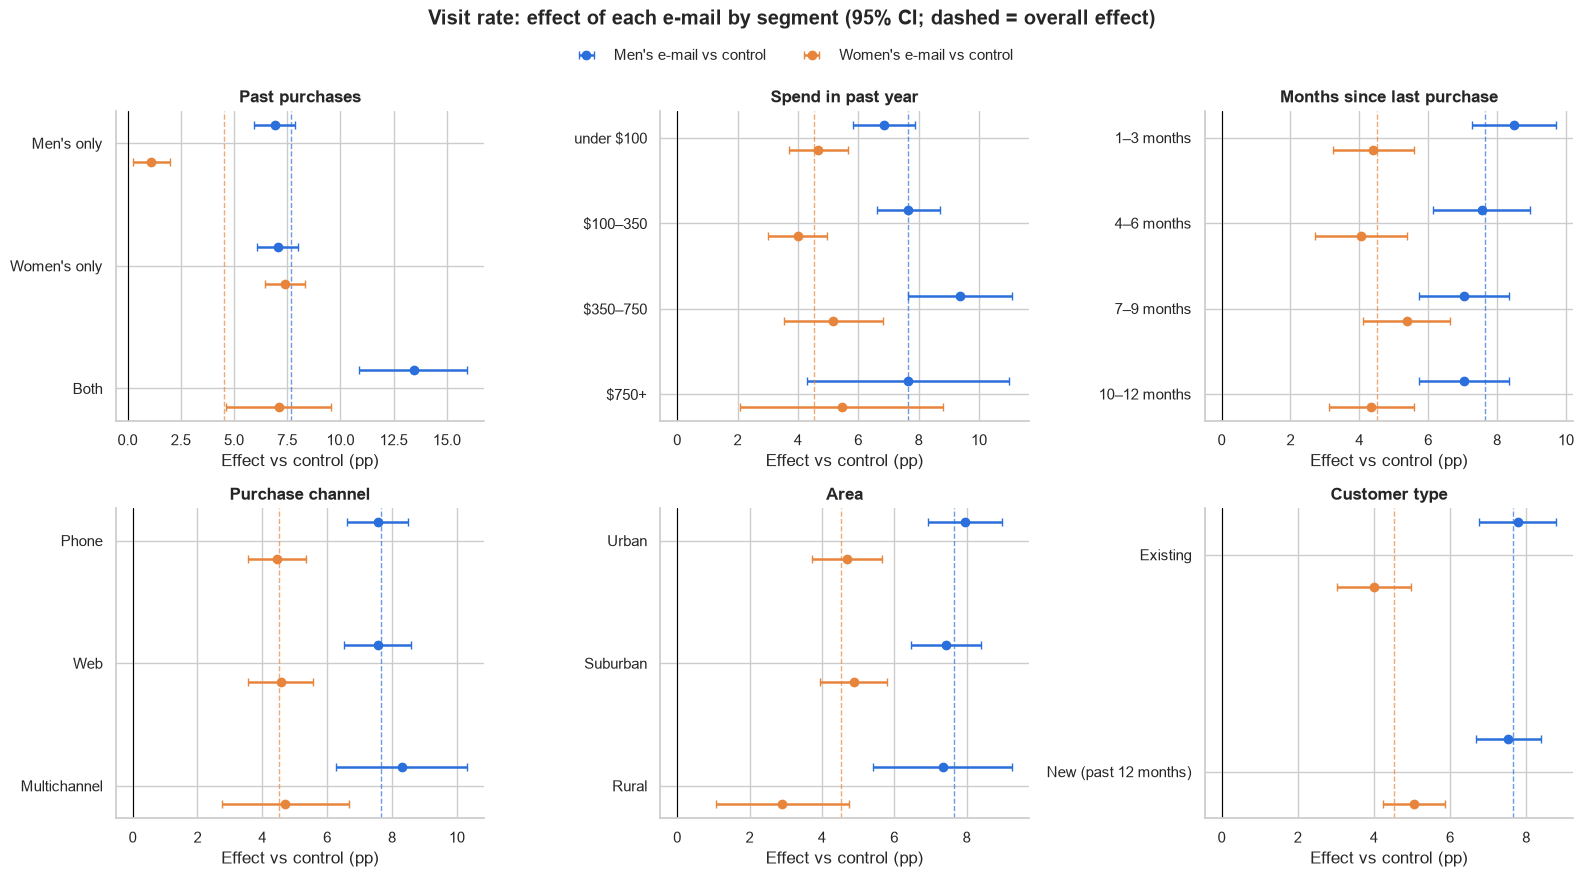

In [6]:
def segment_forest(metric, fname):
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
    scale = 1 if metric == "spend" else 100
    overall = {t: (df.loc[df.treatment == t, metric].mean() - df.loc[df.treatment == "control", metric].mean()) * scale
               for t in ["mens", "womens"]}
    for ax, seg in zip(axes.flat, SEGMENTS):
        levels = list(df[seg].cat.categories)
        for t, offset in [("mens", -0.15), ("womens", 0.15)]:
            sub = seg_res[(seg_res.segment == seg) & (seg_res.metric == metric) & (seg_res.comparison == (t, "control"))]
            sub = sub.set_index("level").reindex(levels)
            y = np.arange(len(levels)) + offset
            ax.errorbar(sub["diff"] * scale, y,
                        xerr=[(sub["diff"] - sub.diff_ci_low) * scale, (sub.diff_ci_high - sub["diff"]) * scale],
                        fmt="o", color=T_COLOR[t], capsize=3, lw=1.8, ms=6, label=f"{T_LABEL[t]} vs control")
            ax.axvline(overall[t], color=T_COLOR[t], ls="--", lw=1, alpha=0.7)
        ax.axvline(0, color="black", lw=0.8)
        ax.set_yticks(range(len(levels)), levels)
        ax.invert_yaxis()
        ax.set_title(SEGMENTS[seg])
        ax.set_xlabel("Effect vs control (USD per customer)" if metric == "spend" else "Effect vs control (pp)")
    fig.suptitle(f"{METRIC_NAMES[metric]}: effect of each e-mail by segment (95% CI; dashed = overall effect)",
                 fontweight="bold", y=1.03)
    fig.tight_layout()
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.savefig(FIG_DIR / fname)
    plt.show()

segment_forest("visit", "03_segment_effects_visit.png")

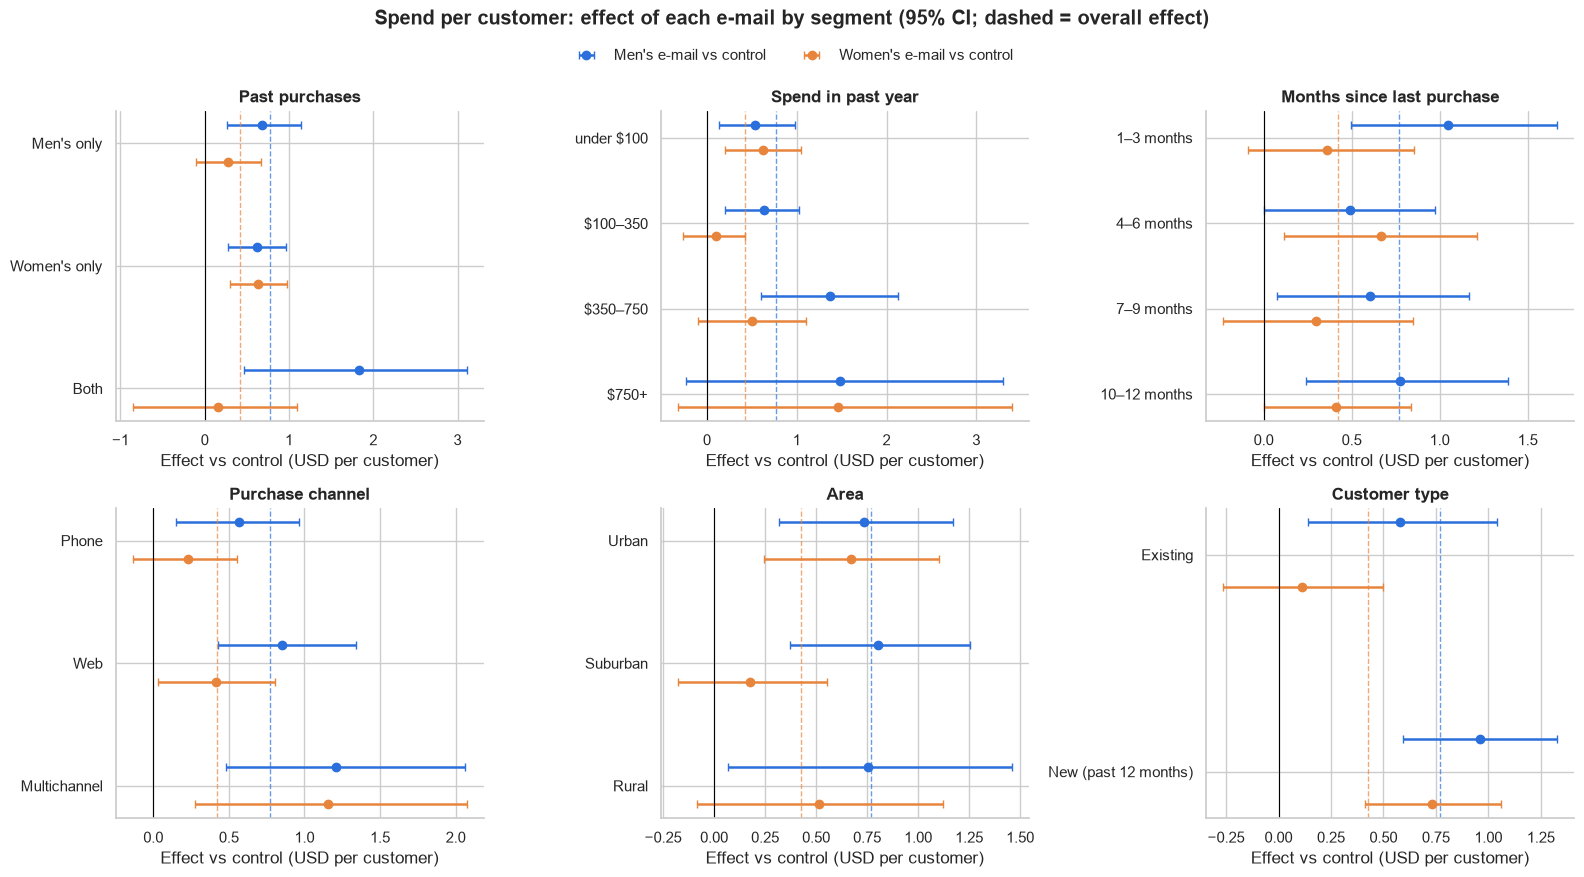

In [7]:
segment_forest("spend", "03_segment_effects_spend.png")

## 4. Are the differences between segments real? Interaction tests

To check whether an e-mail's effect truly **differs** across the levels of a segment variable, we fit one
regression per segment variable and metric:

$$\text{outcome} = \text{e-mail group} + \text{segment} + \text{e-mail group} \times \text{segment}$$

- The **interaction terms** (e-mail × segment) measure how much each e-mail's effect in a segment departs from
  its effect in the reference segment.
- A **Wald test** asks whether all interaction terms are zero together, i.e. "does the effect differ anywhere
  across this variable?".
- **Robust (HC1) standard errors** are used, as in notebook 02, because 0/1 and zero-heavy outcomes are unevenly
  noisy.
- The **Holm correction** is applied across the 6 segment variables within each metric. These are 6 separate
  hypotheses, so an unadjusted p < 0.05 would arise by chance about one time in four.

Effects are compared on the **absolute** scale (percentage points, dollars), because extra buyers and extra
revenue are what the business earns from.

In [8]:
rows = []
for metric in ["visit", "conversion", "spend"]:
    for seg in SEGMENTS:
        fit = smf.ols(f"{metric} ~ C(treatment) * C({seg})", data=df).fit(cov_type="HC1")
        names = [n for n in fit.params.index if ":" in n]
        R = np.zeros((len(names), len(fit.params)))
        for i, n in enumerate(names):
            R[i, fit.params.index.get_loc(n)] = 1
        w = fit.wald_test(R, scalar=True)
        rows.append({"metric": METRIC_NAMES[metric], "segment variable": SEGMENTS[seg],
                     "interaction terms": len(names), "chi2": float(w.statistic), "p_value": float(w.pvalue)})

inter = pd.DataFrame(rows)
inter["p_holm"], inter["effect differs?"] = np.nan, False
for metric, idx in inter.groupby("metric", sort=False).groups.items():
    inter.loc[idx, "p_holm"], inter.loc[idx, "effect differs?"] = holm(inter.loc[idx, "p_value"], alpha=ALPHA)
inter["effect differs?"] = inter["effect differs?"].map({True: "YES", False: "no"})
inter.set_index(["metric", "segment variable"])

interaction terms     chi2  \
metric             segment variable                                         
Visit rate         Past purchases                              4 130.9857   
                   Spend in past year                          6   8.7569   
                   Months since last purchase                  6   8.0266   
                   Purchase channel                            4   0.4890   
                   Area                                        4   4.8083   
                   Customer type                               2   3.7926   
Conversion rate    Past purchases                              4  13.8344   
                   Spend in past year                          6   8.1938   
                   Months since last purchase                  6   2.0468   
                   Purchase channel                            4   4.3241   
                   Area                                        4   1.3443   
                   Customer type                               2   7.0476   
Spend per customer Past purchases                              4   6.8937   
                   Spend in past year                          6   9.4611   
                   Months since last purchase                  6   4.2344   
                   Purchase channel                            4   4.7399   
                   Area                                        4   3.8171   
                   Customer type                               2   5.9296   

                                               p_value  p_holm effect differs?  
metric             segment variable                                             
Visit rate         Past purchases               0.0000  0.0000             YES  
                   Spend in past year           0.1877  0.7509              no  
                   Months since last purchase   0.2362  0.7509              no  
                   Purchase channel             0.9746  0.9746              no  
                   Area                         0.3075  0.7509              no  
                   Customer type                0.1501  0.7506              no  
Conversion rate    Past purchases               0.0078  0.0471             YES  
                   Spend in past year           0.2242  0.8970              no  
                   Months since last purchase   0.9153  1.0000              no  
                   Purchase channel             0.3639  1.0000              no  
                   Area                         0.8538  1.0000              no  
                   Customer type                0.0295  0.1474              no  
Spend per customer Past purchases               0.1416  0.7081              no  
                   Spend in past year           0.1493  0.7081              no  
                   Months since last purchase   0.6450  0.9451              no  
                   Purchase channel             0.3150  0.9451              no  
                   Area                         0.4313  0.9451              no  
                   Customer type                0.0516  0.3094              no

**Result: only one segment variable genuinely changes how customers respond, and that is past purchases.**
- **The effect differs clearly for visits** (χ² = 131, p < 0.0001) **and, after correction, also for
  conversions** (Holm p = 0.047). The shape is clear from sections 2–3:
  - The men's e-mail lifts visits for every type of buyer: +6.9 pp (men's only), +7.1 pp (women's only),
    +13.4 pp (both).
  - The women's e-mail works only on customers who buy women's products: +7.4 pp (women's only) and +7.1 pp (both),
    but just +1.1 pp among men's-only buyers.
- **For spend, no segment variable passes,** including past purchases (unadjusted p = 0.14). This matches the
  warning from notebook 02: segment-level spend is too noisy to show differences of this size.
- **Every other variable** (spend tier, recency, channel, area, new vs existing) shows no reliable difference.
  Customer type on conversion (unadjusted p = 0.03 → Holm 0.15) is exactly the kind of chance finding the correction
  is there to filter out.

## 5. Would targeting pay off?

A **targeting policy** says which e-mail each segment receives. Thanks to randomization, we can estimate what
*any* policy would have earned without running it. Within each segment, the customers who happened to get, say,
the women's e-mail are a fair sample of that whole segment. So:

$$\text{value of policy} = \sum_{\text{segments}} (\text{share of customers in segment}) \times
(\text{average outcome of the e-mail that segment is assigned})$$

### 5a. The pre-specified "matching" policy

Send each customer the e-mail that matches their purchase history: **men's-only buyers → men's e-mail,
women's-only buyers → women's e-mail, buyers of both → men's e-mail** (the overall winner). We compare it with the
simple alternatives. The 95% interval on each policy's difference from "men's e-mail to everyone" comes from a
bootstrap that resamples customers within each group.

In [9]:
SEG = "purchase_history"
policies = {
    "No e-mail": uniform_policy(df, SEG, "control"),
    "Women's e-mail to everyone": uniform_policy(df, SEG, "womens"),
    "Men's e-mail to everyone": uniform_policy(df, SEG, "mens"),
    "Matched to purchase history": {"Men's only": "mens", "Women's only": "womens", "Both": "mens"},
}
baseline = policies["Men's e-mail to everyone"]

rows = []
for name, pol in policies.items():
    row = {"policy": name}
    for metric in ["visit", "conversion", "spend"]:
        row[METRIC_NAMES[metric] + " per 1,000 customers"] = policy_value(df, SEG, metric, pol) * 1000
    if name != "Men's e-mail to everyone":
        d = bootstrap_policy_difference(df, SEG, "spend", pol, baseline, N_BOOT, rng) * 1000
        row["revenue vs men's-to-all (per 1,000)"] = (f"{(policy_value(df, SEG, 'spend', pol) - policy_value(df, SEG, 'spend', baseline)) * 1000:+,.0f} $ "
                                                      f"[{np.percentile(d, 2.5):+,.0f}, {np.percentile(d, 97.5):+,.0f}]")
    else:
        row["revenue vs men's-to-all (per 1,000)"] = "baseline"
    rows.append(row)

policy_table = pd.DataFrame(rows).set_index("policy")
policy_table.columns = ["Visits", "Buyers", "Revenue ($)", "Revenue vs men's-to-all [95% CI]"]
policy_table.style.format({"Visits": "{:,.0f}", "Buyers": "{:,.1f}", "Revenue ($)": "${:,.0f}"})

,Visits,Buyers,Revenue ($),Revenue vs men's-to-all [95% CI]
policy,,,,
No e-mail,106,5.7,$652,"-768 $ [-1,054, -486]"
Women's e-mail to everyone,152,8.8,"$1,078","-342 $ [-671, -36]"
Men's e-mail to everyone,183,12.5,"$1,420",baseline
Matched to purchase history,184,12.2,"$1,427","+7 $ [-177, +185]"


**Result: matching the e-mail to purchase history earns the same as sending the men's e-mail to everyone**
(+\$7 per 1,000 customers, 95% CI −\$177 to +\$185).

The reason: the matching policy only changes what *women's-only buyers* receive, and for them the two e-mails
perform the same (visits 17.0% vs 16.6%, spend \$1.12 vs \$1.11 per customer). So the hypothesis is half right.
The women's e-mail *does* suit women's shoppers, but it is no *better* for them than the men's e-mail, which works
for everyone. Sending the women's e-mail to everyone would lose about \$342 per 1,000 customers (CI −\$671 to −\$36)
compared with sending the men's.

### 5b. Letting the data choose the rule, evaluated honestly

The matching rule is just one idea. What if we let the data pick the best e-mail (or no e-mail) for every level of
a segment variable? To avoid the winner's curse, we use **cross-fitting**:
1. Randomly split the customers into two halves.
2. Learn the rule on half A: for each segment level, pick the arm with the highest average spend.
3. Measure how much more that rule earns than "men's e-mail to everyone" on **half B**, which played no part in
   choosing it.
4. Repeat with 200 different random splits and average.

For comparison, we also show the naive **in-sample** gain (learn and score the rule on the same full data). The gap
between the two is the optimism that the winner's curse would have added.

The "2.5–97.5% range across splits" shows how much the honest gain varies with the luck of the split. It is a
practical gauge of reliability, not a formal confidence interval. Besides the six segment variables we try one
finer rule: past purchases × spend tier (12 cells).

In [10]:
df["purchases_x_spend"] = pd.Categorical(df.purchase_history.astype(str) + " | " + df.history_tier.astype(str))

candidates = {**SEGMENTS, "purchases_x_spend": "Past purchases × spend in past year"}
rows, gain_draws = [], {}
for seg, label in candidates.items():
    full_rule = best_arm_policy(df, seg, "spend")
    in_sample = policy_value(df, seg, "spend", full_rule) - policy_value(df, seg, "spend", uniform_policy(df, seg, "mens"))
    gains = crossfit_gain(df, seg, "spend", "mens", N_SPLITS, rng) * 1000
    gain_draws[label] = gains
    rows.append({"rule based on": label,
                 "in-sample gain ($ / 1,000)": in_sample * 1000,
                 "honest gain ($ / 1,000)": gains.mean(),
                 "2.5% of splits": np.percentile(gains, 2.5), "97.5% of splits": np.percentile(gains, 97.5),
                 "splits with gain > 0": (gains > 0).mean(),
                 "rule chosen on full data": ", ".join(f"{k}: {T_LABEL[v]}" for k, v in full_rule.items() if v != "mens") or "men's e-mail to all"})

crossfit = pd.DataFrame(rows).set_index("rule based on")
crossfit.style.format({c: "{:+,.0f}" for c in crossfit.columns[:4]} | {"splits with gain > 0": "{:.0%}"})

,"in-sample gain ($ / 1,000)","honest gain ($ / 1,000)",2.5% of splits,97.5% of splits,splits with gain > 0,rule chosen on full data
rule based on,,,,,,
Past purchases,+7,-54,-390,+5,9%,Women's only: Women's e-mail
Spend in past year,+31,-51,-359,+47,20%,under $100: Women's e-mail
Months since last purchase,+39,-62,-414,+71,30%,4–6 months: Women's e-mail
Purchase channel,+0,-56,-478,+0,0%,men's e-mail to all
Area,+0,-91,-302,+0,5%,men's e-mail to all
Customer type,+0,-59,-499,+0,0%,men's e-mail to all
Past purchases × spend in past year,+178,-20,-392,+213,50%,"Both | $750+: Women's e-mail, Men's only | $750+: Women's e-mail, Women's only | under $100: Women's e-mail"


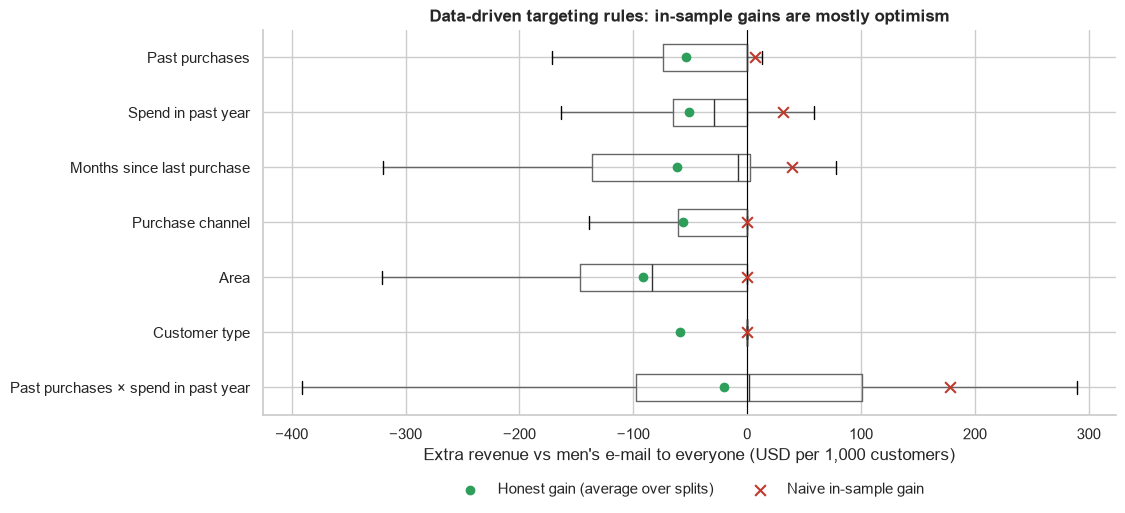

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
labels = list(gain_draws)
ax.boxplot([gain_draws[l] for l in labels], orientation="horizontal", widths=0.5, showfliers=False,
           medianprops={"color": "#333333"}, boxprops={"color": "#666666"}, whiskerprops={"color": "#666666"})
ax.scatter([gain_draws[l].mean() for l in labels], range(1, len(labels) + 1), color="#2e9e5b", zorder=3,
           label="Honest gain (average over splits)")
ax.scatter(crossfit["in-sample gain ($ / 1,000)"].reindex(labels), range(1, len(labels) + 1), marker="x", s=60,
           color="#c0392b", zorder=3, label="Naive in-sample gain")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(1, len(labels) + 1), labels)
ax.invert_yaxis()
ax.set_xlabel("Extra revenue vs men's e-mail to everyone (USD per 1,000 customers)")
ax.set_title("Data-driven targeting rules: in-sample gains are mostly optimism")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.savefig(FIG_DIR / "03_targeting_crossfit.png")
plt.show()

**Result: no data-driven rule beats "men's e-mail to everyone" once it is judged honestly.**
- **In-sample, the rules look profitable.** The finest one (past purchases × spend tier, 12 cells) appears to add
  +\$178 per 1,000 customers.
- **Scored on customers they were not learned from, every rule loses on average** (−\$20 to −\$91 per 1,000). The
  in-sample "gains" were the winner's curse: the rules learned which e-mail got lucky in each small cell.
- **This honest estimate is slightly pessimistic,** because each rule is learned from only half the customers.
  Even so, the best single-variable in-sample gain is only +\$39 per 1,000, far smaller than the noise. Nothing here
  justifies the extra complexity of targeting.

## 6. Which campaign for which segment? (exploratory)

This section turns the analysis into a concrete recommendation for three segment variables the business asked
about. For each segment it covers spend per customer and conversion rate:

| Segment variable | Levels |
|---|---|
| Past purchases | men's only · women's only · both |
| Customer type | existing · new (first purchase in the past 12 months) |
| Purchase channel | phone · web · multichannel |

### ⚠️ Read this first: multiple comparisons
These 8 segments × 3 comparisons × 2 metrics make **48 statistical tests**. At a 5% error rate, about
**2–3 of them would look "significant" by pure chance** even if the e-mails worked identically everywhere. So:
- **Every result in this section is exploratory.** It is a well-founded hypothesis, not proof, and any segment
  rule worth adopting should be confirmed in a follow-up test.
- **The comparison that drives the decision (men's vs women's e-mail) gets a Holm correction** across all
  16 segment × metric combinations, so a segment only counts as "different" if it survives that stricter bar.
- **Section 4 is the formal test for whether effects really differ between segments.** Among these three
  variables, only past purchases did, and only for conversion and visits, not spend.

### Decision rule, fixed before looking at the table
- **Default: the men's e-mail.** It won overall (notebook 02), and one campaign for everyone is the simplest
  to run.
- **Switch a segment to the women's e-mail only if it beats the men's e-mail** on spend or conversion *after* the
  Holm correction. The burden of proof is on the more complex option.
- **The evidence column says how strongly the data supports each choice:**
  - *strong*: the men's e-mail is significantly better after correction;
  - *suggestive*: the men's e-mail is significantly better on at least one metric *before* correction, but not
    after it;
  - *tie*: no significant difference even before correction, so either e-mail would do.

In [12]:
FOCUS = ["purchase_history", "customer_type", "channel"]
focus = seg_res[seg_res.segment.isin(FOCUS) & seg_res.metric.isin(["conversion", "spend"])].copy()
print(f"tests in this section: {len(focus)}  ->  expected false positives at alpha = 0.05: {ALPHA * len(focus):.1f}")

# Holm across the 16 decision-relevant men's-vs-women's comparisons (8 segments x 2 metrics)
h2h = focus[focus.comparison == ("mens", "womens")].copy()
h2h["p_holm"], h2h["sig_holm"] = holm(h2h.p_value, alpha=ALPHA)
print(f"men's vs women's comparisons significant before correction: {(h2h.p_value < ALPHA).sum()} of {len(h2h)}, "
      f"after Holm: {h2h.sig_holm.sum()}")

def recommend(conv, spend):
    sig = [(name, r) for name, r in [("conversion", conv), ("spend", spend)] if r.sig_holm]
    if any(r["diff"] < 0 for _, r in sig):
        return "Women's e-mail", "strong: women's significantly better on " + " & ".join(n for n, r in sig if r["diff"] < 0)
    if sig:
        return "Men's e-mail", "strong: men's significantly better on " + " & ".join(n for n, _ in sig)
    raw = [n for n, r in [("conversion", conv), ("spend", spend)] if r.p_value < ALPHA and r["diff"] > 0]
    if raw:
        return "Men's e-mail", f"suggestive: men's better on {' & '.join(raw)} before correction only"
    return "Men's e-mail (either works)", "tie: no meaningful difference; men's keeps one campaign"

def cell(r, metric):
    f = (lambda v: f"{'+' if v >= 0 else '−'}${abs(v):.2f}") if metric == "spend" else (lambda v: f"{v * 100:+.2f} pp")
    return f"{f(r['diff'])} [{f(r.diff_ci_low)}, {f(r.diff_ci_high)}]"

rows = []
for seg in FOCUS:
    for level in df[seg].cat.categories:
        get = lambda metric, comp: focus[(focus.segment == seg) & (focus.level == level) &
                                         (focus.metric == metric) & (focus.comparison == comp)].iloc[0]
        conv, spend = (h2h[(h2h.segment == seg) & (h2h.level == level) & (h2h.metric == m)].iloc[0]
                       for m in ["conversion", "spend"])
        choice, evidence = recommend(conv, spend)
        sub = df[df[seg] == level]
        rows.append({
            "segment": SEGMENTS[seg], "level": level, "customers": len(sub),
            "conversion: control / men's / women's": " / ".join(f"{sub.loc[sub.treatment == t, 'conversion'].mean():.2%}"
                                                                 for t in ["control", "mens", "womens"]),
            "spend: control / men's / women's": " / ".join(f"${sub.loc[sub.treatment == t, 'spend'].mean():.2f}"
                                                           for t in ["control", "mens", "womens"]),
            "men's − women's conversion [95% CI]": cell(conv, "conversion"), "conv. p (Holm)": conv.p_holm,
            "men's − women's spend [95% CI]": cell(spend, "spend"), "spend p (Holm)": spend.p_holm,
            "men's e-mail beats no e-mail on spend?": "yes" if get("spend", ("mens", "control")).diff_ci_low > 0 else "not clearly",
            "recommended campaign": choice, "evidence": evidence,
        })

recs = pd.DataFrame(rows).set_index(["segment", "level"])
recs.style.format({"customers": "{:,}", "conv. p (Holm)": "{:.3f}", "spend p (Holm)": "{:.3f}"})

tests in this section: 48  ->  expected false positives at alpha = 0.05: 2.4
men's vs women's comparisons significant before correction: 7 of 16, after Holm: 2


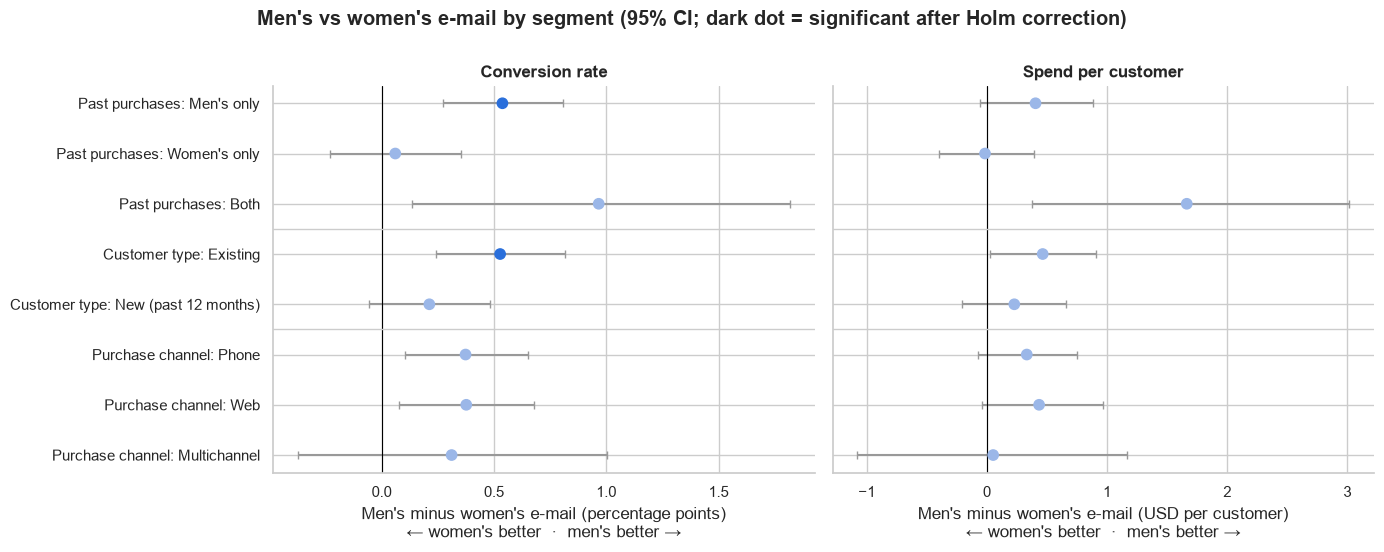

In [13]:
# Men's minus women's e-mail, per segment, on both metrics
order = [(s, lv) for s in FOCUS for lv in df[s].cat.categories]
labels = [f"{SEGMENTS[s]}: {lv}" for s, lv in order]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, metric in zip(axes, ["conversion", "spend"]):
    scale = 1 if metric == "spend" else 100
    sub = h2h[h2h.metric == metric].set_index(["segment", "level"]).loc[order]
    y = np.arange(len(order))
    colors = ["#2a6fdb" if s else "#9bb7e8" for s in sub.sig_holm]
    ax.errorbar(sub["diff"] * scale, y, xerr=[(sub["diff"] - sub.diff_ci_low) * scale, (sub.diff_ci_high - sub["diff"]) * scale],
                fmt="none", ecolor="#999999", capsize=3, lw=1.5)
    ax.scatter(sub["diff"] * scale, y, c=colors, s=55, zorder=3)
    ax.axvline(0, color="black", lw=0.8)
    for boundary in [2.5, 4.5]:  # separate the three segment variables
        ax.axhline(boundary, color="#cccccc", lw=1)
    ax.set_title(METRIC_NAMES[metric])
    unit = "USD per customer" if metric == "spend" else "percentage points"
    ax.set_xlabel(f"Men's minus women's e-mail ({unit})\n← women's better  ·  men's better →")
axes[0].set_yticks(range(len(order)), labels)
axes[0].invert_yaxis()
fig.suptitle("Men's vs women's e-mail by segment (95% CI; dark dot = significant after Holm correction)",
             fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_mens_vs_womens_by_segment.png")
plt.show()

**Result: no segment should get the women's e-mail.**

**Exploratory caveat:** these 8 rows are not 8 separate groups. Every customer appears once under each of the
three variables, so the rows overlap. The recommendations agree with each other, so there is no conflict between
them.

- **The women's e-mail never beat the men's e-mail,** in any of the 16 comparisons, not even before correction.
- **7 of the 16 men's-vs-women's comparisons were significant before correction; only 2 survive Holm:**
  - **men's-only buyers:** the men's e-mail converts +0.54 pp better (1.15% vs 0.61%);
  - **existing customers:** +0.53 pp (1.39% vs 0.87%).

  These are the two segments where sending the women's e-mail would clearly cost sales.
- **Suggestive** (men's ahead before correction only): buyers of both lines, and phone and web buyers.
- **Tie** (no detectable difference): women's-only buyers, new customers and multichannel buyers. Either e-mail
  works equally well for them. If the merchandising team wants to promote the women's range to women's-only
  buyers, the data shows no measurable cost to doing so.

| Segment | Recommended campaign | Strength of evidence |
|---|---|---|
| Bought men's only | Men's e-mail | Strong (conversion) |
| Bought women's only | Either, so men's for simplicity | Tie |
| Bought both | Men's e-mail | Suggestive |
| Existing customer | Men's e-mail | Strong (conversion) |
| New customer | Either, so men's for simplicity | Tie |
| Phone / web buyer | Men's e-mail | Suggestive |
| Multichannel buyer | Either, so men's for simplicity | Tie |

This agrees with section 5. The per-segment view arrives at the same answer: **one campaign, the men's e-mail,
for everyone.**

## 7. Summary

**Question:** should the retailer target each campaign at specific customer segments instead of sending one e-mail?

**Answer: no. Send the men's e-mail to everyone.**

1. **The e-mails do work differently on different buyers, but only by past purchases.**
   - The men's e-mail raises visits among all three types of buyer, and most among customers who buy both
     (+13.4 pp).
   - The women's e-mail barely moves men's-only buyers (+1.1 pp visits vs +7.4 pp among women's-only buyers).
   - This difference is statistically solid for visits and conversions. No other customer attribute (spend tier,
     recency, channel, area, new vs existing) changes the effect in a reliable way.
2. **That difference doesn't create a targeting opportunity.** Where the women's e-mail works (women's-only
   buyers), it only *ties* with the men's e-mail; it never beats it. Matching e-mails to purchase history earns
   +\$7 per 1,000 customers (95% CI −\$177 to +\$185), effectively nothing.
3. **Data-mined rules don't survive honest testing.** Rules picked from the data look up to +\$178 per 1,000 better
   in-sample. Scored on held-out customers, all of them earn *less* than the simple men's-to-everyone strategy.
4. **Segment by segment, the men's e-mail is never worse** (section 6, exploratory).
   - Across past purchases, new vs existing customers, and channel, the women's e-mail never beat the men's e-mail
     on spend or conversion.
   - The men's e-mail is clearly better for men's-only buyers and existing customers (conversion, significant after
     Holm correction).
   - The two e-mails tie for women's-only buyers, new customers and multichannel buyers.
5. **What we can't conclude.** Segment-level spend is noisy: only effects of roughly \$1.45+ per customer would be
   detectable in a ~1,000-customer segment. A modest targeting gain in revenue can't be ruled out, but there is no
   evidence for one. Anyone proposing targeting should test it in a follow-up experiment with that policy as its
   own arm.

**Business takeaway:** the men's e-mail is the better *single* campaign *and* there is no profitable segment for
which to swap it out. Keep the campaign simple.

**One idea for future campaigns:** the men's e-mail had its biggest effect on customers who buy from both lines.
That suggests broad, mixed-assortment creative may outperform gender-specific creative. This hypothesis is worth
testing directly.

**Outputs:** `figures/03_purchase_history.png`, `figures/03_segment_effects_visit.png`,
`figures/03_segment_effects_spend.png`, `figures/03_targeting_crossfit.png`, `figures/03_mens_vs_womens_by_segment.png`.